In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
sys.path.append('../../MARS')
sys.path.append('../../MARS/run_lars/code_3d')

from MARS.run_lars.code_3d.utils import EarlyStopping, LRScheduler
import os
import pandas as pd
import torch.backends.cudnn as cudnn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import numpy as np
import time
import tqdm
import shutil
import yaml
import sys
from datetime import datetime 
import time
import random
import wandb
import optuna
import plotly
from matplotlib import pyplot as plt

from MARS.run_lars.code_3d import dataset
from MARS.run_lars.code_3d import utils
from MARS.run_lars.code_3d import logging_utils_3D

import pickle


In [4]:
model = utils.model_prediction('/gpfs/data/mayerhoeferlab/projects/lars/lars3d_chpt/LARS_trained_state-dict_0.pth')
model = model.cuda()
model.eval()


/gpfs/home/kn2347/MARS/notebooks/../../MARS/MARS/run_lars/code_3d/utils.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ch = torch.load(chpnt)


my_model(
  (features): Sequential(
    (0): Conv3d(1, 64, kernel_size=(7, 7, 7), stride=(2, 2, 2), padding=(3, 3, 3), bias=False)
    (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool3d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (bn1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (bn2): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (bn1): BatchNorm3d(64, eps=1e-05, momentum=0.1, 

In [5]:
data_path_img='/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/'
data_path='/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/train_df.csv'
trainds =dataset.get_datasets_3d('train', norm=True,transform=None, data_path_img=data_path_img, data_path=data_path,
                postfilter_fwhm_xy_mm=6.4, normalize_mean=0, normalize_std=1, target_label_name = 'PET_jco',
                postfilter_fwhm_xy_mm_min=None, postfilter_fwhm_xy_mm_max=None, fixed_suv_clip=1000000000)

In [6]:
loss_fn = torch.nn.BCEWithLogitsLoss()


In [7]:
# create dataloader
loader = torch.utils.data.DataLoader(trainds, batch_size=4, shuffle=False, num_workers=0)


In [9]:
def operate(mu, sigma, q):
    avg_loss = 0
    avg_auc = 0

    gt_collector = []
    prob_collector = []
    for i, (x,y) in enumerate(loader):
        if i>7:
            break
        x = x.cuda()
        x = torch.clip(x, 0, q)
        x = (x - mu) / sigma
        with torch.no_grad():
            pred2 = model(x)
            pred = pred2[:,1]


        # compute loss between logits and ground truth
        loss = loss_fn(pred.squeeze().cpu(), y.float().cpu())
        avg_loss += loss.item()

        gt_collector.append(y.detach().cpu().numpy())
        prob_collector.append(F.softmax(pred2, dim=1)[:,1].detach().cpu().numpy())

    gt_collector = np.concatenate(gt_collector)
    prob_collector = np.concatenate(prob_collector)

    # compute probabilities, and then AUC against the ground truth
    auc = logging_utils_3D.calculate_metrics_from_probs(prob_collector, gt_collector)['auc']

    avg_loss /= i
    return avg_loss, auc

In [10]:
def optimize_using_optuna(trial):
    mu = trial.suggest_float('mu', -20.0, 20)
    sigma = trial.suggest_float('sigma', 0.01, 200)
    q = trial.suggest_float('q', 15, 200)
    return operate(mu, sigma, q)

study = optuna.create_study(directions=["minimize", "maximize"])
study.optimize(optimize_using_optuna, n_trials=100)

import pickle
pickle.dump(study, open('/gpfs/home/kn2347/MARS/MARS/normalization_optuna_study3.pkl', 'wb'))


[I 2025-10-20 15:32:24,331] A new study created in memory with name: no-name-23986db6-00e3-43db-9b95-e60c1b3deb72
[W 2025-10-20 15:32:46,466] Trial 0 failed with parameters: {'mu': 1.4194431504616603, 'sigma': 80.46391219426947, 'q': 132.40469053169494} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/optuna/study/_optimize.py", line 201, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_2487932/1191490870.py", line 5, in optimize_using_optuna
    return operate(mu, sigma, q)
  File "/tmp/ipykernel_2487932/644833266.py", line 7, in operate
    for i, (x,y) in enumerate(loader):
  File "/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 701, in __next__
    data = self._next_data()
  File "/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 757, 

KeyboardInterrupt: 

In [ ]:
list_elems = []
num_elements_total = 0
for i, (x,y) in tqdm.tqdm(enumerate(loader), total = len(loader)):
    x = torch.clip(x, 0, 189.74741039173838)
    list_elems.append(x.detach().cpu().numpy())

    if i% 10==0:
        print(np.concatenate(list_elems).mean())
        print(np.concatenate(list_elems).std())
        print('==========')

avg = np.concatenate(list_elems).mean()
std = np.concatenate(list_elems).std()

In [24]:
print(avg)
print(std)

0.09219918
0.4826449


[FrozenTrial(number=66, state=TrialState.COMPLETE, values=[0.6821954622864723, 0.5670995670995671], datetime_start=datetime.datetime(2025, 10, 16, 15, 4, 17, 236035), datetime_complete=datetime.datetime(2025, 10, 16, 15, 5, 37, 640405), params={'mu': 0.784645979644992, 'sigma': 121.33582288667978, 'q': 185.7694000378635}, user_attrs={}, system_attrs={'NSGAIISampler:generation': 1}, intermediate_values={}, distributions={'mu': FloatDistribution(high=20.0, log=False, low=-20.0, step=None), 'sigma': FloatDistribution(high=200.0, log=False, low=0.01, step=None), 'q': FloatDistribution(high=200.0, log=False, low=15.0, step=None)}, trial_id=66, value=None),
 FrozenTrial(number=71, state=TrialState.COMPLETE, values=[1.8856018632650375, 0.5757575757575758], datetime_start=datetime.datetime(2025, 10, 16, 15, 10, 58, 195314), datetime_complete=datetime.datetime(2025, 10, 16, 15, 12, 18, 139612), params={'mu': 0.784645979644992, 'sigma': 35.99184645712848, 'q': 189.74741039173838}, user_attrs={},

In [12]:
len(loader)

185

In [38]:
study.optimize(optimize_using_optuna, n_trials=200)

[I 2025-10-14 20:23:47,315] Trial 27 finished with value: 49.172247648239136 and parameters: {'mu': 8.739084578313896, 'sigma': 46.58674433700373}. Best is trial 17 with value: 1.6081860214471817.
[I 2025-10-14 20:27:13,755] Trial 28 finished with value: 4.507536515593529 and parameters: {'mu': -2.9629491123515024, 'sigma': 35.37803193795302}. Best is trial 17 with value: 1.6081860214471817.
[I 2025-10-14 20:30:39,217] Trial 29 finished with value: 32.42502176761627 and parameters: {'mu': -16.297237933877227, 'sigma': 36.01234044267447}. Best is trial 17 with value: 1.6081860214471817.
[I 2025-10-14 20:34:04,763] Trial 30 finished with value: 133.23582363128662 and parameters: {'mu': 18.32967133510849, 'sigma': 38.43809245499983}. Best is trial 17 with value: 1.6081860214471817.
[I 2025-10-14 20:37:30,642] Trial 31 finished with value: 220.73552894592285 and parameters: {'mu': 32.78133804947779, 'sigma': 41.901895509411595}. Best is trial 17 with value: 1.6081860214471817.
[I 2025-10-1

KeyboardInterrupt: 

In [43]:
import plotly

In [49]:
print(plotly.__version__)

6.3.1


/tmp/ipykernel_3202329/1139446409.py:1: ExperimentalWarning: optuna.visualization.matplotlib._contour.plot_contour is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_contour(study, params=None, target=None, target_name='Objective Value')


array([[<Axes: xlabel='mu', ylabel='mu'>,
        <Axes: xlabel='q', ylabel='mu'>,
        <Axes: xlabel='sigma', ylabel='mu'>],
       [<Axes: xlabel='mu', ylabel='q'>, <Axes: xlabel='q', ylabel='q'>,
        <Axes: xlabel='sigma', ylabel='q'>],
       [<Axes: xlabel='mu', ylabel='sigma'>,
        <Axes: xlabel='q', ylabel='sigma'>,
        <Axes: xlabel='sigma', ylabel='sigma'>]], dtype=object)

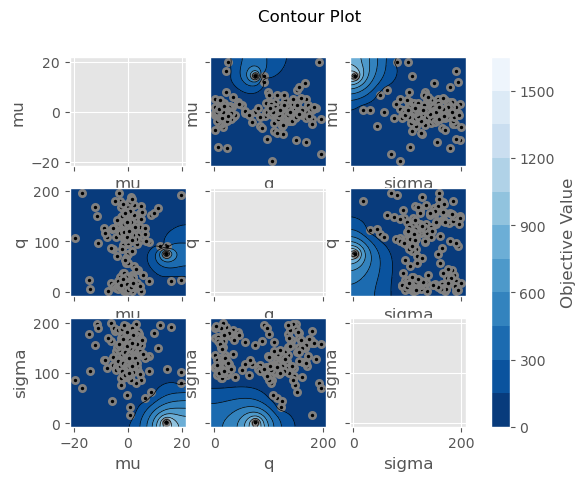

In [13]:
optuna.visualization.matplotlib.plot_contour(study, params=None, target=None, target_name='Objective Value')

In [50]:
import pickle
pickle.dump(study, open('/gpfs/home/kn2347/MARS/MARS/normalization_optuna_study.pkl', 'wb'))

In [4]:
study = pickle.load(open('/gpfs/home/kn2347/MARS/MARS/normalization_optuna_study.pkl', 'rb'))

In [14]:
study.best_params

{'mu': 0.0384886240731242,
 'sigma': 107.31245549102623,
 'q': 11.524219620363338}

In [ ]:
fig = optuna.visualization.plot_contour(study, params=None, target=None, target_name='Objective Value')
fig

In [17]:
def get_log(trial):
    x = trial.value
    if x is None:
        return None
    return np.log2(x) if x>0 else -3

In [18]:
fig = optuna.visualization.plot_contour(study, params=None, target=get_log, target_name='Val Loss')
fig

In [ ]:
# combo 1: (mu, sigma, q) = (0.0384886, 107.312, 11.524)
# combo 2: (mu, sigma, q) = (-.2914, 108.603, 94.913)
# combo 3: (1.69, 174.6, 33.33)
# combo 4: (.177, 161.1, 56.82)

In [28]:
study.best_params

{'mu': 0.0384886240731242,
 'sigma': 107.31245549102623,
 'q': 11.524219620363338}

In [30]:
rr = trainds[0][0]

In [34]:
torch.max(rr)

tensor(88.6392)

In [ ]:
optuna.visualization.plot_slice(study, params=None, target=get_log, target_name='Objective Value')

In [20]:
study.n_objectives

AttributeError: 'Study' object has no attribute 'n_objectives'

In [23]:
optuna.visualization.plot_pareto_front(study, include_dominated_trials=True, axis_order=None, constraints_func=None, target_names='Objective Value')

ValueError: `plot_pareto_front` function only supports 2 or 3 objective studies when using `targets` is `None`. Please use `targets` if your objective studies have more than 3 objectives.